# Below Zero: analysis

This notebook reads only from the local cache in `data/raw/`. It never calls the API. To populate the cache, run the fetch script from the project root first, e.g. `python src/fetch.py 2024-04-07`.

## Stage 01: one day, end to end

One settlement day of Market Index Data (`MID`), the wholesale price series for phenomenon 1. The aim is to learn the response shape and the settlement-period conventions before looping over three years.

Day chosen: **Sunday 7 April 2024**, the 2024 day with the most negative `MID` periods (found with a one-off scan of 2024).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from plotnine import *

sys.path.append(str(Path("..") / "src"))
from fetch import mid_cache_path
from parse import parse_mid, periods_in_day

DAY = "2024-04-07"
FIG_DIR = Path("..") / "figures"

### What the raw response looks like

A JSON object with a `data` list, one record per provider per settlement period.

In [2]:
path = mid_cache_path(DAY)
raw = json.loads(path.read_text(encoding="utf-8"))
print("top-level keys:", list(raw))
for record in raw["data"][:2]:
    print(record)

raw_df = pd.DataFrame(raw["data"])
raw_df.groupby("dataProvider").agg(
    rows=("price", "size"),
    min_price=("price", "min"),
    max_price=("price", "max"),
    total_volume_mwh=("volume", "sum"),
)

top-level keys: ['data']
{'dataset': 'MID', 'startTime': '2024-04-07T22:30:00Z', 'dataProvider': 'APXMIDP', 'settlementDate': '2024-04-07', 'settlementPeriod': 48, 'price': 28.73, 'volume': 1553.0}
{'dataset': 'MID', 'startTime': '2024-04-07T22:30:00Z', 'dataProvider': 'N2EXMIDP', 'settlementDate': '2024-04-07', 'settlementPeriod': 48, 'price': 0.0, 'volume': 0.0}


,rows,min_price,max_price,total_volume_mwh
dataProvider,,,,
APXMIDP,48,-61.09,68.49,89213.75
N2EXMIDP,48,0.00,0.00,0.00


### Parsed: one row per settlement period

`parse_mid` keeps the APX rows only, builds the timestamp from `(settlementDate, settlementPeriod)`, checks it against the API's own `startTime`, and checks that every period 1..N is present exactly once.

In [3]:
mid = parse_mid(path)
negative = mid["price_gbp_mwh"] < 0
print(f"periods: {len(mid)}")
print(f"negative periods: {negative.sum()} ({negative.mean():.0%})")
print(f"lowest price: £{mid['price_gbp_mwh'].min():.2f}/MWh")
print(f"highest price: £{mid['price_gbp_mwh'].max():.2f}/MWh")
mid.head()

periods: 48
negative periods: 29 (60%)
lowest price: £-61.09/MWh
highest price: £68.49/MWh


,settlement_date,settlement_period,start_utc,start_local,price_gbp_mwh,volume_mwh
0,2024-04-07,1,2024-04-06 23:00:00+00:00,2024-04-07 00:00:00+01:00,-0.66,1436.95
1,2024-04-07,2,2024-04-06 23:30:00+00:00,2024-04-07 00:30:00+01:00,7.46,1578.60
2,2024-04-07,3,2024-04-07 00:00:00+00:00,2024-04-07 01:00:00+01:00,11.51,1801.35
3,2024-04-07,4,2024-04-07 00:30:00+00:00,2024-04-07 01:30:00+01:00,19.46,2043.65
4,2024-04-07,5,2024-04-07 01:00:00+00:00,2024-04-07 02:00:00+01:00,4.89,2170.00


### Clock-change check

The number of periods in a day comes from the length of the local day, never an assumed 48.

In [4]:
for d in ["2024-03-31", DAY, "2024-10-27"]:
    print(d, periods_in_day(d))

2024-03-31 46
2024-04-07 48
2024-10-27 50


### Chart

Drawn as steps because each price holds for the whole half hour. Negative periods are marked by both colour and shape, so the chart still reads in greyscale.

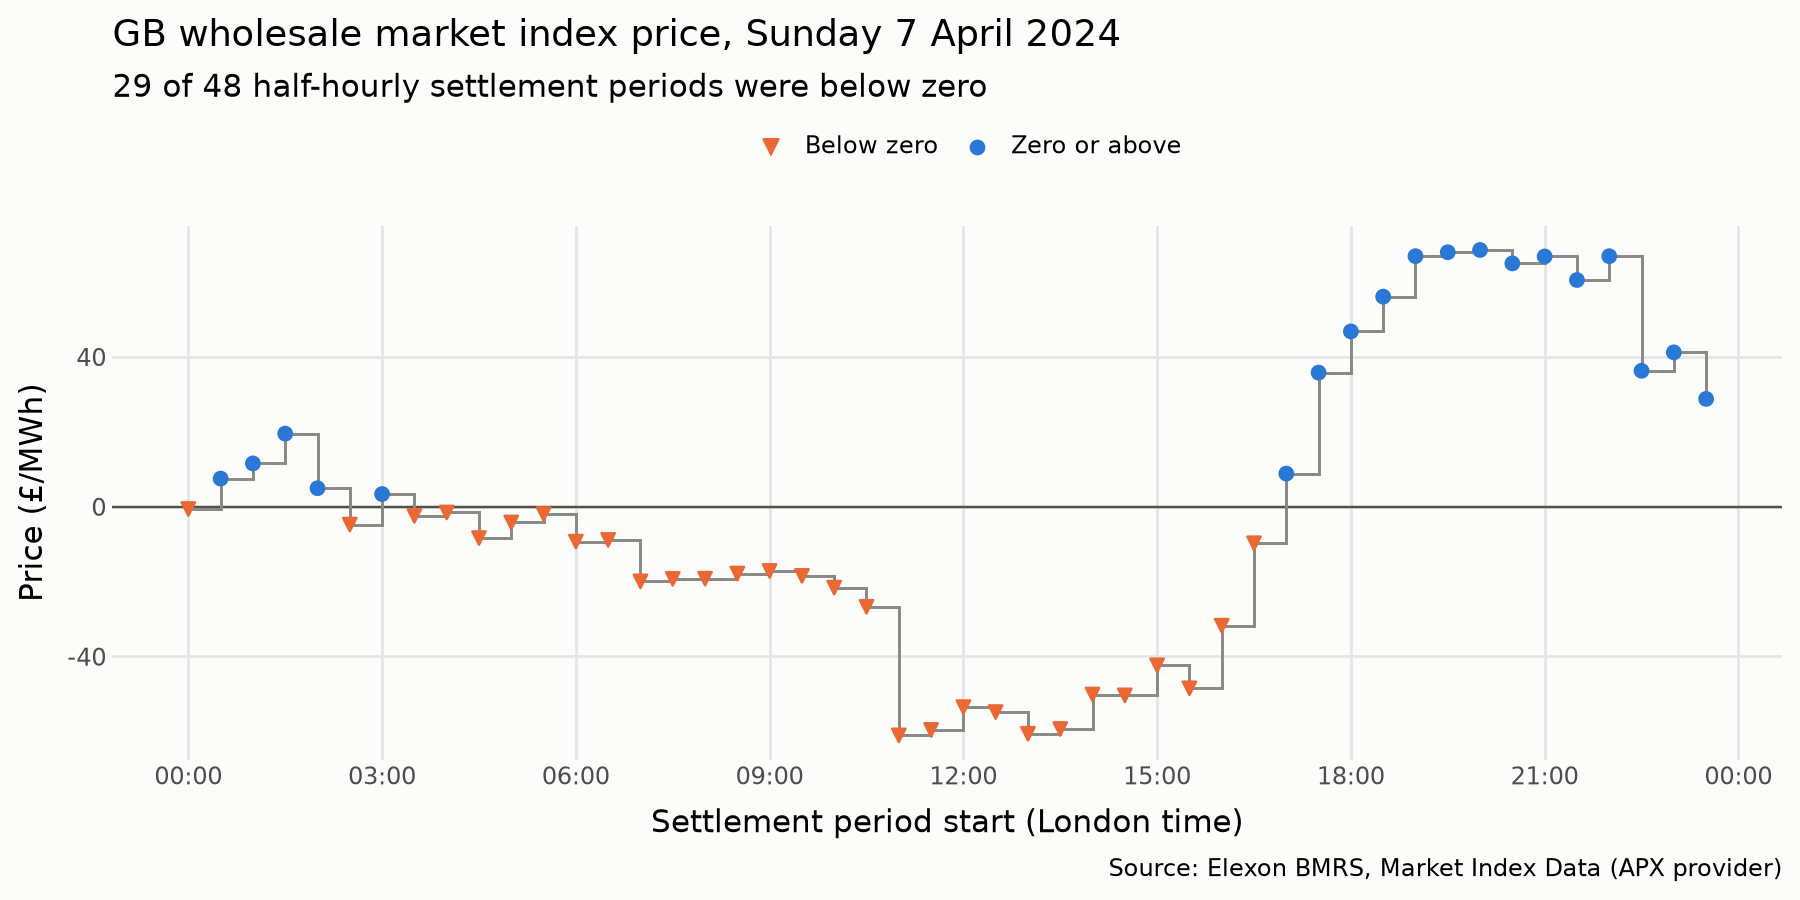

In [5]:
plot_df = mid.assign(
    # Local wall-clock time for the x-axis. Safe here because 7 April has no clock change.
    time=mid["start_local"].dt.tz_localize(None),
    sign=negative.map({True: "Below zero", False: "Zero or above"}),
)

fig = (
    ggplot(plot_df, aes("time", "price_gbp_mwh"))
    + geom_hline(yintercept=0, color="#52514e", size=0.5)
    # "hv" = flat for the half hour, then jump: each price applies to its whole period
    + geom_step(direction="hv", color="#8a8985", size=0.6)
    + geom_point(aes(color="sign", shape="sign"), size=2.2)
    + scale_color_manual(values={"Below zero": "#eb6834", "Zero or above": "#2a78d6"})
    + scale_shape_manual(values={"Below zero": "v", "Zero or above": "o"})
    + scale_x_datetime(date_labels="%H:%M", date_breaks="3 hours")
    + labs(
        title="GB wholesale market index price, Sunday 7 April 2024",
        subtitle=f"{negative.sum()} of {len(mid)} half-hourly settlement periods were below zero",
        x="Settlement period start (London time)",
        y="Price (£/MWh)",
        color="", shape="",
        caption="Source: Elexon BMRS, Market Index Data (APX provider)",
    )
    + theme_minimal(base_size=11)
    + theme(
        figure_size=(9, 4.5),
        legend_position="top",
        panel_grid_minor=element_blank(),
        plot_background=element_rect(fill="#fcfcfb", color="#fcfcfb"),
    )
)
fig.save(FIG_DIR / f"stage01_mid_{DAY}.png", dpi=150, verbose=False)
fig